[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L1/BA_L1_onchain/BA_L1_onchain.ipynb)

# BA_L1_onchain: Four Views of a Blockchain

*Quantlet of Lecture 1, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Usage, fees, security and value of Bitcoin and Ethereum: transactions per day and average fee per transaction (30-day means), the Bitcoin hash rate and market capitalisation, daily, November 2014 to 8 October 2025, on log scales. The raw market-value series shows an 11-day recording error.

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

In [4]:
plt.rcParams.update({'font.size': 10, 'axes.labelsize': 10, 'axes.titlesize': 10, 'lines.linewidth': 1.5})   # as in the slide charts


def load_onchain(name):
    # daily on-chain series, one column per coin, as numbers (missing values are NaN)
    return onchain(name).apply(pd.to_numeric, errors='coerce')


def slide_legend(fig, bottom, ncol=3):
    # one legend for the whole figure, under the plots, as in the slides
    fig.legend(loc='lower center', ncol=ncol, frameon=False, fontsize=8)
    fig.tight_layout(rect=(0, bottom, 1, 1))

## Data and method

Four daily series describe a blockchain:

- **usage**: transactions per day;
- **fees**: the average fee per transaction in USD, the price of using the network;
- **security**: the Bitcoin hash rate in exahashes per second (EH/s, $10^{18}$ hashes per second), the computing power
  an attacker would have to match;
- **value**: market capitalisation, price times coins in circulation, in USD bn.

Usage and fees are smoothed with a 30-day moving mean, $\bar x_t = \frac{1}{30}\sum_{j=0}^{29} x_{t-j}$ (at least 20
non-missing days). All panels use log scales, so equal distances are equal ratios.

**How to read the chart.** The market-value panel shows the raw series: Bitcoin's value is more than 1 000 times too
small on 11 days, 27 August to 6 September 2023 (red arrow), a recording error of the data source. These days are set
to missing before any number is computed.

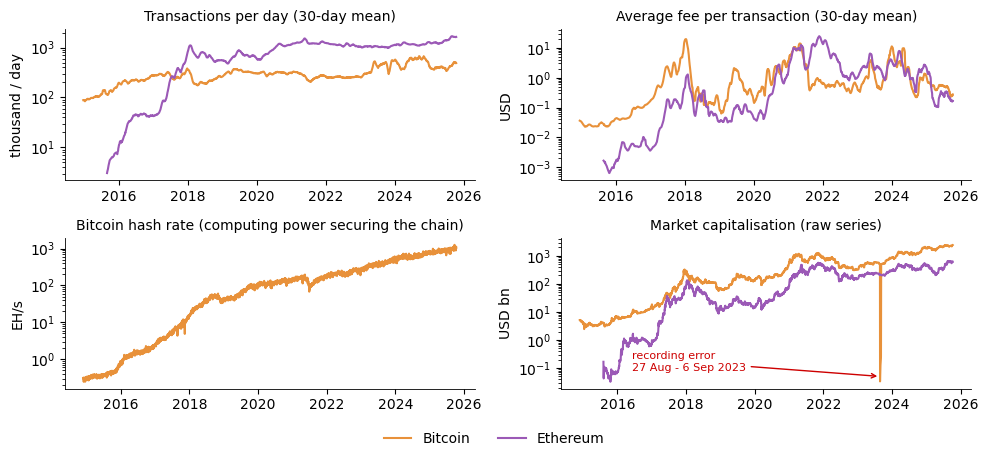

In [5]:
tx, fee = load_onchain('transaction'), load_onchain('transactionfee')
hr, mc = load_onchain('hashrate'), load_onchain('Mktcap')
roll = lambda s: s.rolling(30, min_periods=20).mean()          # 30-day moving mean

fig, ax = plt.subplots(2, 2, figsize=(10, 4.6))
ax[0, 0].plot(roll(tx['BTC']) / 1e3, color=BTC, label='Bitcoin')
ax[0, 0].plot(roll(tx['ETH']) / 1e3, color=ETH, label='Ethereum')
ax[0, 0].set_ylabel('thousand / day'); ax[0, 0].set_title('Transactions per day (30-day mean)', fontsize=10)
ax[0, 1].plot(roll(fee['BTC']), color=BTC); ax[0, 1].plot(roll(fee['ETH']), color=ETH)
ax[0, 1].set_ylabel('USD'); ax[0, 1].set_title('Average fee per transaction (30-day mean)', fontsize=10)
ax[1, 0].plot(hr['BTC'] / 1e18, color=BTC)
ax[1, 0].set_ylabel('EH/s'); ax[1, 0].set_title('Bitcoin hash rate (computing power securing the chain)', fontsize=10)
ax[1, 1].plot(mc['BTC'] / 1e9, color=BTC); ax[1, 1].plot(mc['ETH'] / 1e9, color=ETH)
ax[1, 1].set_ylabel('USD bn'); ax[1, 1].set_title('Market capitalisation (raw series)', fontsize=10)
ax[1, 1].annotate('recording error\n27 Aug - 6 Sep 2023', xy=(pd.Timestamp('2023-08-27'), 0.05),
                  xytext=(pd.Timestamp('2016-06-01'), 0.08), fontsize=8, color=RED,
                  arrowprops=dict(arrowstyle='->', color=RED))
for a in ax.flat:
    a.set_yscale('log')
fig.legend(*ax[0, 0].get_legend_handles_labels(), loc='lower center', ncol=2, frameon=False)
fig.tight_layout(rect=(0, 0.06, 1, 1))
save_fig(fig, 'ba_l1_onchain')

mc.loc['2023-08-27':'2023-09-06', 'BTC'] = np.nan          # remove the recording error

The numbers quoted on the slides "Four Views of a Blockchain" and "Reading the Four Panels".

In [6]:
last = tx.index.max()
print(f'Sample: {tx.index.min():%d %B %Y} to {last:%d %B %Y}')
print(f'Bitcoin transactions per day, mean of January 2015:  {tx.loc["2015-01", "BTC"].mean():>12,.0f}')
for c, name in [('BTC', 'Bitcoin'), ('ETH', 'Ethereum')]:
    print(f'{name} transactions per day, 30-day mean on {last:%d %b %Y}: {roll(tx[c]).dropna().iloc[-1]:>12,.0f}')
print(f'Ethereum / Bitcoin transactions (30-day means): {roll(tx["ETH"]).dropna().iloc[-1] / roll(tx["BTC"]).dropna().iloc[-1]:.1f}')
for c, name in [('BTC', 'Bitcoin'), ('ETH', 'Ethereum')]:
    f = roll(fee[c])
    print(f'{name} average fee (30-day mean): peak {f.max():.2f} USD on {f.idxmax():%d %B %Y}; last {f.dropna().iloc[-1]:.3f} USD')
h = hr['BTC'].dropna()
print(f'Bitcoin hash rate: {h.iloc[0] / 1e18:.2f} EH/s on {h.index[0]:%d %B %Y}, {h.iloc[-1] / 1e18:,.0f} EH/s on '
      f'{h.index[-1]:%d %B %Y}, a factor of {h.iloc[-1] / h.iloc[0]:,.0f}')
print(f'Market value on {last:%d %B %Y}: Bitcoin {mc["BTC"].dropna().iloc[-1] / 1e9:,.0f} USD bn, '
      f'Ethereum {mc["ETH"].dropna().iloc[-1] / 1e9:,.0f} USD bn')

Sample: 28 November 2014 to 08 October 2025
Bitcoin transactions per day, mean of January 2015:        93,112
Bitcoin transactions per day, 30-day mean on 08 Oct 2025:      488,729
Ethereum transactions per day, 30-day mean on 08 Oct 2025:    1,628,106
Ethereum / Bitcoin transactions (30-day means): 3.3
Bitcoin average fee (30-day mean): peak 19.81 USD on 13 January 2018; last 0.275 USD
Ethereum average fee (30-day mean): peak 24.79 USD on 25 November 2021; last 0.168 USD
Bitcoin hash rate: 0.30 EH/s on 28 November 2014, 1,079 EH/s on 08 October 2025, a factor of 3,568
Market value on 08 October 2025: Bitcoin 2,442 USD bn, Ethereum 620 USD bn
